# 実験結果の解析

In [40]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path.cwd().resolve()
if not (project_dir / "configs").is_dir():
    project_dir = project_dir.parent
experiment_name = "exp_v2_grid_search"
experiment_dir = project_dir / "data" / experiment_name
required_files = ["config_used.json", "raw_data.csv", "summary_data.csv"]
if any(not (experiment_dir / name).is_file() for name in required_files):
    raise FileNotFoundError(f"実験を先に実行してください: {experiment_dir}")
with (experiment_dir / "config_used.json").open(encoding="utf-8") as file:
    config = json.load(file)
raw_df = pd.read_csv(experiment_dir / "raw_data.csv")
summary_df = pd.read_csv(experiment_dir / "summary_data.csv")
config


{'experiment_name': 'exp_v2_grid_search',
 'agent_class': 'AgentV2',
 'field_class': 'FieldV2',
 'simulation': {'total_steps': 200000,
  'eval_start_step': 100001,
  'num_runs': 1,
  'base_seed': 43,
  'workers': 5},
 'grid_parameters': {'death_threshold': {'start': -200, 'stop': 0, 'step': 10},
  'mutation_rate': [0.0],
  'transfer_amount': [5]},
 'fixed_field_parameters': {'field_size': 10,
  'initial_agents': 20,
  'initial_food_prob': 0.1,
  'step_food_prob': 0.003,
  'food_durability': 5.0,
  'energy_loss_per_step': 0.1,
  'reward_food': 1.0,
  'clone_threshold': 100.0}}

In [41]:
time_series_path = experiment_dir / "time_series_data.csv"
time_series_df = None
if time_series_path.is_file():
    time_series_df = pd.read_csv(time_series_path)
    if time_series_df.empty:
        print("時系列データは空です。1000step以上の実験を実行してください。")
    else:
        display(time_series_df)
else:
    print("時系列データがありません。実験を再実行して time_series_data.csv を作成してください。")

,death_threshold,mutation_rate,transfer_amount,run_id,seed,step,population,altruism_count
0,-200,0.0,5,0,43,101000,14,11165
1,-200,0.0,5,0,43,102000,16,12247
2,-200,0.0,5,0,43,103000,16,13440
3,-200,0.0,5,0,43,104000,16,13488
4,-200,0.0,5,0,43,105000,15,12860
...,...,...,...,...,...,...,...,...
1995,-10,0.0,5,0,43,196000,15,11588
1996,-10,0.0,5,0,43,197000,15,12334
1997,-10,0.0,5,0,43,198000,11,12377
1998,-10,0.0,5,0,43,199000,12,8411


,death_threshold,mutation_rate,transfer_amount,run_id,seed,step,population,altruism_count
0,-200,0.0,5,0,43,101000,14,11165
1,-200,0.0,5,0,43,102000,16,12247
2,-200,0.0,5,0,43,103000,16,13440
3,-200,0.0,5,0,43,104000,16,13488
4,-200,0.0,5,0,43,105000,15,12860
...,...,...,...,...,...,...,...,...
95,-200,0.0,5,0,43,196000,14,11224
96,-200,0.0,5,0,43,197000,14,11457
97,-200,0.0,5,0,43,198000,15,12361
98,-200,0.0,5,0,43,199000,15,12312


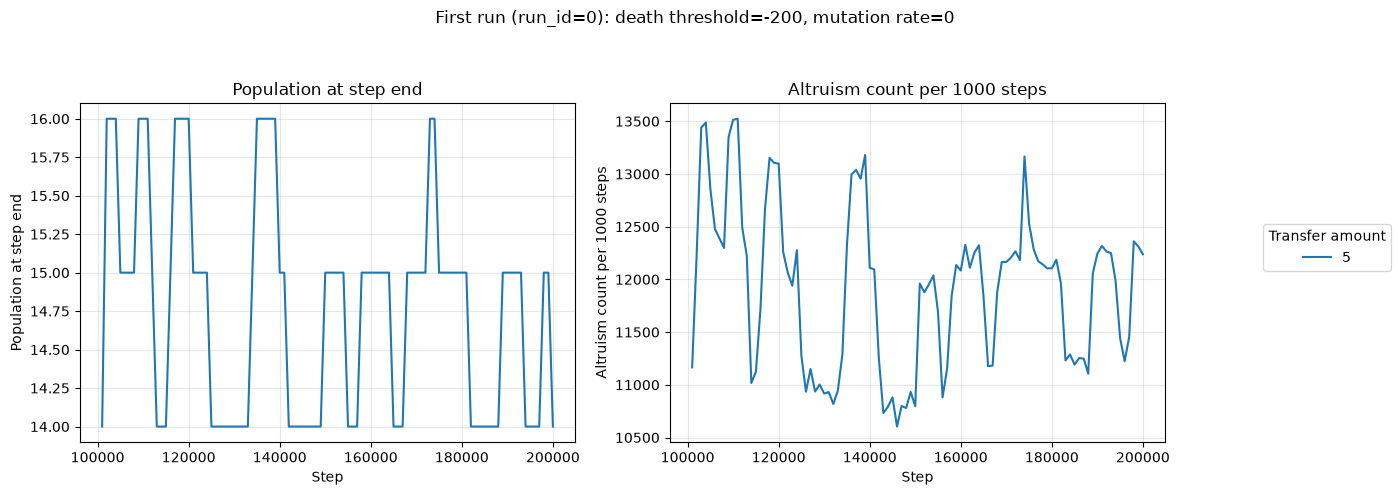

In [ ]:
if time_series_df is not None and not time_series_df.empty:
    # 比較したい値に変更してください。
    selected_death_threshold = time_series_df["death_threshold"].min()
    selected_mutation_rate = time_series_df["mutation_rate"].min()

    selected_time_series = time_series_df.loc[
        (time_series_df["death_threshold"] == selected_death_threshold)
        & (time_series_df["mutation_rate"] == selected_mutation_rate)
    ]
    if selected_time_series.empty:
        print("選択した条件の時系列データがありません。")
    else:
        display(selected_time_series)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
        for transfer_amount, transfer_df in selected_time_series.groupby("transfer_amount", sort=True):
            transfer_df = transfer_df.sort_values("step")
            for metric, axis in zip(["population", "altruism_count"], axes):
                axis.plot(transfer_df["step"], transfer_df[metric], label=f"{transfer_amount:g}")
        for label, axis in zip(["Population at step end", "Altruism count per 1000 steps"], axes):
            axis.set_title(label)
            axis.set_xlabel("Step")project/notebooks/analysis_exp_v3.ipynb
            axis.set_ylabel(label)
            axis.grid(True, alpha=0.3)
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, title="Transfer amount", loc="center right")
        fig.suptitle(
            f"First run (run_id=0): death threshold={selected_death_threshold:g}, "
            f"mutation rate={selected_mutation_rate:g}"
        )
        fig.tight_layout(rect=(0, 0, 0.85, 0.93))
        plt.show()


In [43]:
display(raw_df.head())
raw_df.describe()


,run_id,seed,avg_population,std_population,avg_altruism_count,std_altruism_count,death_threshold,mutation_rate,transfer_amount
0,0,43,14.77844,0.687703,11.92173,1.726683,-200,0.0,5
1,0,43,14.51989,0.627526,12.06609,1.530819,-190,0.0,5
2,0,43,14.44706,0.594778,12.10962,1.515660,-180,0.0,5
3,0,43,13.93339,0.709491,11.77518,1.511773,-170,0.0,5
4,0,43,13.94055,0.532784,11.15304,1.626599,-160,0.0,5


,run_id,seed,avg_population,std_population,avg_altruism_count,std_altruism_count,death_threshold,mutation_rate,transfer_amount
count,20.0,20.0,20.000000,20.000000,20.000000,20.000000,20.000000,20.0,20.0
mean,0.0,43.0,14.296219,0.770407,11.746790,1.643706,-105.000000,0.0,5.0
std,0.0,0.0,0.359192,0.155333,0.398734,0.152589,59.160798,0.0,0.0
min,0.0,43.0,13.336270,0.532784,10.669640,1.472552,-200.000000,0.0,5.0
25%,0.0,43.0,14.172138,0.683641,11.669250,1.527820,-152.500000,0.0,5.0
50%,0.0,43.0,14.423810,0.736726,11.823945,1.607495,-105.000000,0.0,5.0
75%,0.0,43.0,14.526093,0.814913,12.036915,1.733594,-57.500000,0.0,5.0
max,0.0,43.0,14.778440,1.212236,12.166670,2.086122,-10.000000,0.0,5.0


In [44]:
summary_df


,death_threshold,mutation_rate,transfer_amount,num_runs,avg_population,std_population,avg_within_run_std_population,avg_altruism_count,std_altruism_count,avg_within_run_std_altruism_count
0,-200,0.0,5,1,14.77844,NaN,0.687703,11.92173,NaN,1.726683
1,-190,0.0,5,1,14.51989,NaN,0.627526,12.06609,NaN,1.530819
2,-180,0.0,5,1,14.44706,NaN,0.594778,12.10962,NaN,1.515660
3,-170,0.0,5,1,13.93339,NaN,0.709491,11.77518,NaN,1.511773
4,-160,0.0,5,1,13.94055,NaN,0.532784,11.15304,NaN,1.626599
5,-150,0.0,5,1,13.33627,NaN,0.855371,11.24149,NaN,1.499978
6,-140,0.0,5,1,14.67591,NaN,0.710451,12.10977,NaN,1.620051
7,-130,0.0,5,1,14.52649,NaN,0.661168,12.16667,NaN,1.540128
8,-120,0.0,5,1,14.52596,NaN,0.719577,12.14919,NaN,1.571177
9,-110,0.0,5,1,14.50383,NaN,0.749234,11.89291,NaN,1.648899


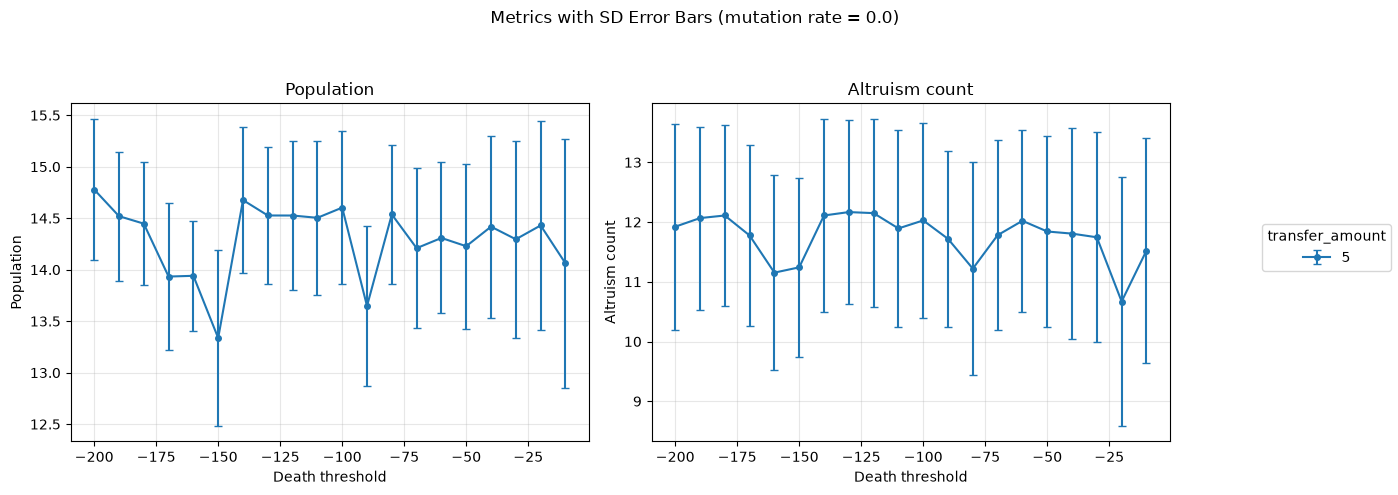

In [45]:
import matplotlib.pyplot as plt

plot_metrics = [
    ("avg_population", "avg_within_run_std_population", "Population"),
    ("avg_altruism_count", "avg_within_run_std_altruism_count", "Altruism count"),
]

if "transfer_amount" in summary_df.columns:
    transfer_col = "transfer_amount"
else:
    raise KeyError("summary_df に 'transfer_amount' の列が存在しません。")

transfer_amounts = sorted(summary_df[transfer_col].unique())
colors = plt.get_cmap("tab10")
transfer_colors = {
    amount: colors(index % colors.N)
    for index, amount in enumerate(transfer_amounts)
}

for mutation_rate, condition_df in summary_df.groupby("mutation_rate", sort=True):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

    for (mean_metric, std_metric, label), axis in zip(plot_metrics, axes):
        for transfer_amount, transfer_df in condition_df.groupby(transfer_col, sort=True):
            transfer_df = transfer_df.sort_values("death_threshold")

            x = transfer_df["death_threshold"]
            y = transfer_df[mean_metric]
            yerr = transfer_df[std_metric] if std_metric in transfer_df.columns else None
            
            axis.errorbar(
                x,
                y,
                yerr=yerr,
                fmt="-o",
                markersize=4,
                capsize=3,
                capthick=1,
                color=transfer_colors[transfer_amount],
                label=f"{transfer_amount}",
            )

        axis.set_title(label)
        axis.set_xlabel("Death threshold")
        axis.set_ylabel(label)
        axis.grid(True, alpha=0.3)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title=transfer_col, loc="center right")
    fig.suptitle(f"Metrics with SD Error Bars (mutation rate = {mutation_rate})")

    fig.tight_layout(rect=(0, 0, 0.85, 0.93))
    plt.show()

## 利他行動の有無による人口の比較

`exp_v1_grid_search`（利他行動をしない村）と `exp_v2_grid_search`（利他行動をする村）の条件別集計を比較。

平均人口は `avg_population`、標準偏差は `avg_within_run_std_population`（評価期間中の人口の標準偏差を試行間で平均した値）。



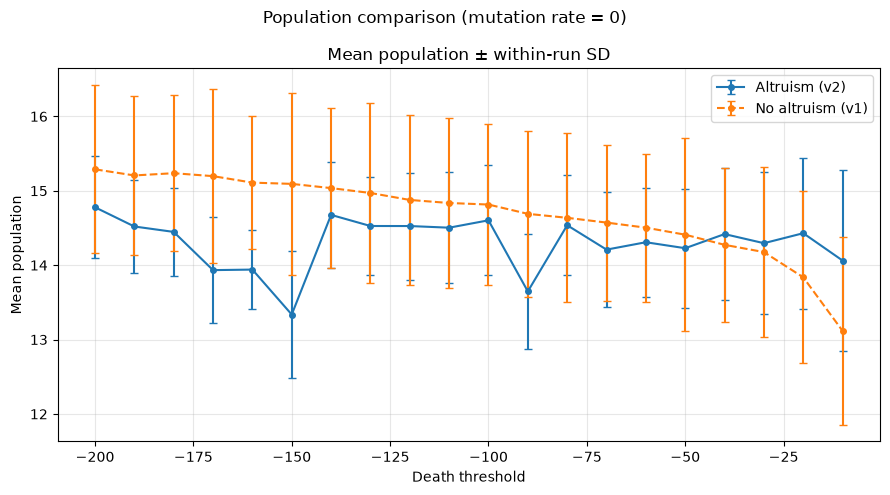

In [46]:
# 両実験の summary_data.csv を読み込み、既存の summary_df は保持する。
population_comparison_frames = []
for comparison_experiment, village_label in [
    ("exp_v1_grid_search", "No altruism (v1)"),
    ("exp_v2_grid_search", "Altruism (v2)"),
]:
    comparison_path = project_dir / "data" / comparison_experiment / "summary_data.csv"
    if not comparison_path.is_file():
        raise FileNotFoundError(f"実験を先に実行してください: {comparison_path}")
    comparison_frame = pd.read_csv(comparison_path)
    required_columns = {
        "death_threshold", "mutation_rate", "transfer_amount",
        "avg_population", "avg_within_run_std_population",
    }
    missing_columns = required_columns - set(comparison_frame.columns)
    if missing_columns:
        raise ValueError(f"{comparison_path} に必要な列がありません: {sorted(missing_columns)}")
    if comparison_frame.empty:
        raise ValueError(f"集計データが空です: {comparison_path}")
    population_comparison_frames.append(comparison_frame.assign(village=village_label))

population_comparison_df = pd.concat(population_comparison_frames, ignore_index=True)

for mutation_rate, condition_df in population_comparison_df.groupby("mutation_rate", sort=True):
    fig, axis = plt.subplots(figsize=(9, 5))
    for (village, transfer_amount), parameter_df in condition_df.groupby(
        ["village", "transfer_amount"], sort=True
    ):
        parameter_df = parameter_df.sort_values("death_threshold")
        label = f"{village}"
        line_style = "--" if village == "No altruism (v1)" else "-"
        axis.errorbar(
            parameter_df["death_threshold"],
            parameter_df["avg_population"],
            yerr=parameter_df["avg_within_run_std_population"],
            fmt=line_style + "o", markersize=4, capsize=3, label=label,
        )

    axis.set_title("Mean population ± within-run SD")
    axis.set_xlabel("Death threshold")
    axis.set_ylabel("Mean population")
    axis.grid(True, alpha=0.3)
    axis.legend()
    fig.suptitle(f"Population comparison (mutation rate = {mutation_rate:g})")
    fig.tight_layout()
    plt.show()
